# Teaching a toy NanoGPT arithmetic and algebra with DPO

## Team contributions

| Member | Contribution |
|---|---|
| Shi Qi | training |
| Natasha | data generation and training|
| Zayd| evaluation and write up |

## Overview

The NanoGPT in `../sft/gpt.pt` was pretrained only on character-level QA chit-chat. When asked a math question it refuses
(we verify this in Task 1). The goal is to use **Direct Preference Optimisation (DPO)** to make it prefer a correct,
explained answer (*positive*) over an unhelpful one (*negative*).

| Task | Where in this notebook |
|---|---|
| Task 1: build ≈100k positive/negative pairs | Task 1 section (after Step 4) |
| Task 2: load data, optimiser, training loop | Steps 5–7 |
| Task 3: test the fine-tuned model | Step 8 |
| Task 4: explanations and analysis | Markdown cells throughout, summary at the end |

**How to run:** run every cell top to bottom from inside the `dpo/` folder. Training picks CUDA, then Apple MPS, then CPU.
Training runs 15 epochs. On an Apple-silicon laptop (MPS) one epoch takes about 12–14 minutes (≈3–3.5 h in total); on a CUDA GPU it is much faster.

### Step 1: Install necessary packages

In [1]:
%pip install -q matplotlib torch numpy tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


### Step 2: Package imports and configuration

All random seeds are fixed so that data generation, training and evaluation are reproducible.

* `beta` controls how sharply the preference loss separates positive from negative.
* `sft_weight` weights an extra term that directly maximises the likelihood of the positive answer.
  The data has only one wording per answer, so this "SFT" term does most of the work of teaching the
  model *which digits* to write; the preference term teaches it to *answer instead of refusing*.

In [2]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
import copy
import re
import json
import time
from collections import Counter, defaultdict
from model import GPT, GPTConfig
from tqdm import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Configuration
beta = 0.5
sft_weight = 0.1
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available() and torch.backends.mps.is_built():
    device = 'mps'
else:
    device = 'cpu'
print("Selected device:", device)
base_lr = 3e-4
epochs = 15
batch_size = 64
max_length = 64
max_new_tokens = 100

# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])

Selected device: mps


### Step 3: Define helper functions

* `compute_logprob` returns the **average per-token log-probability** of each sequence in a batch. Token id 0 is
  `'\n'`, which is also used for padding, so it is ignored.
* `pad_or_truncate` pads every sequence to `max_length` so a batch can be stacked into one tensor.
* `get_batches` shuffles the pairs every epoch and yields `(negative, positive)` tensors.
* `answer` runs greedy decoding (`top_k=1`) for one prompt. Greedy decoding makes the test deterministic: sampling
  at temperature 0.8 sometimes picks a wrong digit even when the model "knows" the right one.

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

@torch.no_grad()
def answer(model, prompt):
    x = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    y = model.generate(x, max_new_tokens=max_new_tokens, top_k=1)
    return decode(y[0][0].tolist())

### Step 4: Load the pretrained NanoGPT model

In [4]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
gptconf = GPTConfig(**ckpt['model_args'])
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()
print(f"Parameters: {sum(p.numel() for p in gpt.parameters())/1e6:.2f}M")

Parameters: 8.84M


## Task 1: Build positive–negative data pairs

### 1.1 What does the pretrained model say to math questions?

The brief suggests generating negative samples with the pretrained NanoGPT. Before generating 100k of them, we
first ask the untrained model 120 math questions of every type and count what it replies.

In [5]:
gpt.eval()
probe_prompts = ([f"{random.randint(0,199)}+{random.randint(0,199)}=?" for _ in range(20)]
               + [f"{random.randint(100,199)}-{random.randint(0,99)}=?" for _ in range(20)]
               + [f"{random.randint(1,30)}*{random.randint(0,200)}=?" for _ in range(20)]
               + [f"{(b:=random.randint(1,50))*random.randint(0,200)}/{b}=?" for _ in range(20)]
               + [f"x+{random.randint(0,199)}={random.randint(200,399)},x=?" for _ in range(20)]
               + [f"x*{(a:=random.randint(1,30))}={a*random.randint(0,200)},x=?" for _ in range(20)])
pretrained_replies = Counter(answer(gpt, p)[len(p):].strip() for p in probe_prompts)
gpt.train()
for reply, n in pretrained_replies.most_common(5):
    print(f"{n:4d} x  {reply!r}")
model_refusal = pretrained_replies.most_common(1)[0][0]

 115 x  "Sorry, I don't know."
   3 x  "Sory, I don't know."
   2 x  "I don't know."


**Observation:** the pretrained model answers essentially every math question with the same refusal,
`"Sorry, I don't know."`. So "negatives generated by the pretrained NanoGPT" would all be this one string, and
running the model 100k times would cost minutes for no benefit. We therefore use a fixed refusal as the negative:
`"Sorry, I do not know."`, the sample file's negative with the `'!'` removed (`'!'` is not in the vocabulary, see
Step 5).

### 1.2 Generating positive answers

Positive answers follow the format of the sample file, `"<question> The answer is <ans> because <working> equals <ans>."`.
Because every answer is arithmetic, we compute it exactly in Python instead of asking ChatGPT. This guarantees
100% correct labels, costs nothing, and scales to 100k items.

**Question types (12).** These cover all four operations and all positions of the unknown, so the model sees every
form the TAs' examples use (`17+19=?`, `3*17=?`, `72/4=?`, `72-x=34,x=?`, `x*11=44,x=?`):

| Type | Example | Working shown |
|---|---|---|
| addition / subtraction | `74+8=?`, `79-7=?` | same expression |
| multiplication / division | `3*17=?`, `72/4=?` | same expression |
| `a+x=b`, `x+a=b` | `x+55=95,x=?` | `b-a` |
| `a-x=b`, `x-a=b` | `72-x=34,x=?` | `a-b`, `b+a` |
| `a*x=b`, `x*a=b` | `x*11=44,x=?` | `b/a` |
| `a/x=b`, `x/a=b` | `x/4=18,x=?` | `a/b`, `a*b` |

**Design decisions and improvements over our first version.**
1. *Rebalanced the types.* Our first dataset (100.5k pairs) had only 3.5k multiplication and 4k division questions,
   against 26–28k for each algebra family. The first model reached 80–85% on addition and algebra but only 20–25% on
   multiplication and division. We widened the operand ranges for `*` and `/` (one operand 0–30, the other 0–200, in
   either order; divisors up to 50), which gives enough *distinct* questions to raise these types to about 10k each.
2. *No duplicates.* Every question appears once, so we can later test on questions that are guaranteed to be unseen.
3. *Only answers that are non-negative integers.* Divisions are built as `(b·ans)/b`, so they are always exact.
4. *Fits the context.* The longest pair plus the padding newlines fits within `max_length = 64` characters, so no
   question is truncated (checked below).

In [6]:
random.seed(SEED)

def make_question(eq_type):
    # returns (prompt, answer, working) for one random question of the given type
    if eq_type == 'addition':
        a, b = random.randint(0, 199), random.randint(0, 199)
        return f"{a}+{b}=?", a + b, f"{a}+{b}"
    if eq_type == 'subtraction':
        a, b = random.randint(0, 199), random.randint(0, 199)
        if b > a:
            a, b = b, a
        return f"{a}-{b}=?", a - b, f"{a}-{b}"
    if eq_type == 'multiplication':
        a, b = random.randint(0, 30), random.randint(0, 200)
        if random.random() < 0.5:
            a, b = b, a
        return f"{a}*{b}=?", a * b, f"{a}*{b}"
    if eq_type == 'division':
        b, ans = random.randint(1, 50), random.randint(0, 200)
        return f"{b*ans}/{b}=?", ans, f"{b*ans}/{b}"
    if eq_type == 'addition_unknown':          # a+x=b
        a, ans = random.randint(0, 199), random.randint(0, 199)
        return f"{a}+x={a+ans},x=?", ans, f"{a+ans}-{a}"
    if eq_type == 'addition2_unknown':         # x+a=b
        a, ans = random.randint(0, 199), random.randint(0, 199)
        return f"x+{a}={a+ans},x=?", ans, f"{a+ans}-{a}"
    if eq_type == 'subtraction_unknown':       # a-x=b
        b, ans = random.randint(0, 199), random.randint(0, 199)
        return f"{ans+b}-x={b},x=?", ans, f"{ans+b}-{b}"
    if eq_type == 'subtraction2_unknown':      # x-a=b
        ans = random.randint(0, 199)
        a = random.randint(0, ans)
        return f"x-{a}={ans-a},x=?", ans, f"{ans-a}+{a}"
    if eq_type == 'multiplication_unknown':    # a*x=b
        a, ans = random.randint(1, 30), random.randint(0, 200)
        return f"{a}*x={a*ans},x=?", ans, f"{a*ans}/{a}"
    if eq_type == 'multiplication2_unknown':   # x*a=b
        a, ans = random.randint(1, 30), random.randint(0, 200)
        return f"x*{a}={a*ans},x=?", ans, f"{a*ans}/{a}"
    if eq_type == 'division_unknown':          # a/x=b
        ans, b = random.randint(1, 30), random.randint(1, 200)
        return f"{ans*b}/x={b},x=?", ans, f"{ans*b}/{b}"
    if eq_type == 'division2_unknown':         # x/a=b
        a, b = random.randint(1, 30), random.randint(0, 200)
        return f"x/{a}={b},x=?", a * b, f"{a}*{b}"
    raise ValueError(eq_type)

samples_per_type = {
    'addition': 12000, 'subtraction': 12000,
    'multiplication': 10000, 'division': 9000,
    'addition_unknown': 9000, 'addition2_unknown': 9000,
    'subtraction_unknown': 9000, 'subtraction2_unknown': 9000,
    'multiplication_unknown': 5500, 'multiplication2_unknown': 5500,
    'division_unknown': 5500, 'division2_unknown': 5500,
}

def positive_text(prompt, ans, working):
    return f"{prompt} The answer is {ans} because {working} equals {ans}."

negative_answer = "Sorry, I do not know."

data, seen_prompts = [], set()
for eq_type, target in samples_per_type.items():
    generated = attempts = 0
    while generated < target and attempts < target * 50:
        attempts += 1
        prompt, ans, working = make_question(eq_type)
        if prompt in seen_prompts:
            continue
        seen_prompts.add(prompt)
        data.append({"prompt": prompt, "type": eq_type, "answer": ans,
                     "negative": f"{prompt} {negative_answer}",
                     "positive": positive_text(prompt, ans, working)})
        generated += 1
    assert generated == target, f"{eq_type} came up short: {generated}/{target}"
    print(f"{eq_type:24s} {generated:6d}")

random.shuffle(data)
with open("pos_neg_pairs.json", "w") as f:
    json.dump(data, f)

# sanity checks
assert len(data) == sum(samples_per_type.values()) == len(seen_prompts)
assert all(c in stoi for p in data for c in p['positive'] + p['negative'])
assert max(len(p['positive']) + 4 for p in data) <= max_length
for p in data[:20000]:   # every positive must contain the true answer
    q = p['prompt'].split(',')[0].replace('=?', '')
    if 'x' not in q:
        assert eval(q) == p['answer'], p
print(f"\nSaved {len(data)} unique pairs to pos_neg_pairs.json")

addition                  12000
subtraction               12000
multiplication            10000
division                   9000
addition_unknown           9000
addition2_unknown          9000
subtraction_unknown        9000
subtraction2_unknown       9000
multiplication_unknown     5500
multiplication2_unknown    5500
division_unknown           5500
division2_unknown          5500



Saved 101000 unique pairs to pos_neg_pairs.json


### Step 5: Load data

We reload the pairs from the JSON file (so this step also works on its own if the file was made earlier). We also
drop any character that is not in the tokenizer's vocabulary. For example `'!'` is not in `stoi`, so the
`"Sorry, I do not know!"` from the sample file could not be encoded. This filter is only a safeguard: the generator
above only produces valid characters.

**Oversampling the hardest types (our addition).** Our previous model was weakest on the two question types whose
answer is a *product* of two numbers: `a*b=?` (35%) and `x/a=b` (30%). It had already reached 95–100% on
addition, subtraction and their algebra forms. We therefore repeat the pairs of these two types once more in
the training list, so the model sees them twice per epoch. The JSON file itself still contains each question
exactly once.

In [7]:
print(stoi.keys())

dict_keys(['\n', ' ', "'", '*', '+', ',', '-', '.', '/', '=', '?', '’', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'])


In [8]:
with open("pos_neg_pairs.json") as f:
    lines = json.load(f)

for pair in lines:
    for key in ['negative', 'positive']:
        pair[key] = "".join(char for char in pair[key] if char in stoi)

print("Total number of pairs:", len(lines))
print("Pairs per type:", dict(Counter(p['type'] for p in lines)))

oversampled_types = {'multiplication', 'division2_unknown'}
lines = lines + [p for p in lines if p['type'] in oversampled_types]
print("Training pairs per epoch after oversampling:", len(lines))

random.seed(1)
for item in random.sample(lines, 6):
    print("  -", item['negative'])
    print("  +", item['positive'])

Total number of pairs: 101000
Pairs per type: {'division': 9000, 'subtraction_unknown': 9000, 'addition': 12000, 'division_unknown': 5500, 'subtraction2_unknown': 9000, 'multiplication': 10000, 'subtraction': 12000, 'division2_unknown': 5500, 'multiplication2_unknown': 5500, 'addition2_unknown': 9000, 'addition_unknown': 9000, 'multiplication_unknown': 5500}
Training pairs per epoch after oversampling: 116500
  - 15+161=? Sorry, I do not know.
  + 15+161=? The answer is 176 because 15+161 equals 176.
  - 870/10=? Sorry, I do not know.
  + 870/10=? The answer is 87 because 870/10 equals 87.
  - 4*1=? Sorry, I do not know.
  + 4*1=? The answer is 4 because 4*1 equals 4.
  - 160*20=? Sorry, I do not know.
  + 160*20=? The answer is 3200 because 160*20 equals 3200.
  - 21*24=? Sorry, I do not know.
  + 21*24=? The answer is 504 because 21*24 equals 504.
  - x+85=255,x=? Sorry, I do not know.
  + x+85=255,x=? The answer is 170 because 255-85 equals 170.


### Step 6: Build the optimizer and scheduler

* **AdamW** gives each parameter an adaptive learning rate, and its decoupled weight decay regularises the
  fine-tuning and reduces overfitting.

* **Cosine annealing** lowers the learning rate smoothly from `3e-4` towards 0 over the 15 epochs. Large updates
  early help the model learn the answer format quickly; small updates late let it settle on the exact digits.

* **Dropout is switched off for fine-tuning (our addition).** The pretrained model uses dropout 0.2, which
  regularises open-ended chit-chat. Arithmetic needs exact, deterministic digit patterns, and with 100k examples
  overfitting is not the main risk, so we set every dropout rate to 0. This covers both the `nn.Dropout` layers
  and the `dropout_p` that `model.py` passes to `scaled_dot_product_attention`.

**Why 15 epochs and `lr = 3e-4` instead of the template's 5 epochs and `1e-4`?** When we re-ran the template
settings from scratch, the model always produced the right *format* after 5 epochs, but the right *number* only
about 7% of the time (see *Experiments* at the end). The preference term saturates within the first epoch, so the
model learns the arithmetic slowly, through the SFT term. It needs more and larger updates. Cosine decay keeps the learning rate
high for most of the run, whereas StepLR (halving every 2 epochs) had already reduced it to 1/4 by epoch 5.

In [9]:
for module in gpt.modules():
    if isinstance(module, nn.Dropout):
        module.p = 0.0
    elif isinstance(getattr(module, 'dropout', None), float):   # CausalSelfAttention's flash-attention dropout
        module.dropout = 0.0
print("Dropout layers disabled:", sum(isinstance(m, nn.Dropout) for m in gpt.modules()))

optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

Dropout layers disabled: 19


### Step 7: Begin training

For each batch we compute the average log-probability of the positive and the negative answer and minimise

$$\mathcal{L} = -\log\sigma\Big(\tfrac{\log\pi(y^+) - \log\pi(y^-)}{\beta}\Big) \;-\; 0.1\cdot\log\pi(y^+), \quad \beta = 0.5$$

* The **preference term** pushes the positive above the negative, so the model learns to answer instead of refusing.
* The **SFT term** keeps raising the likelihood of the correct answer even after the preference term has
  saturated. Because the refusal is so different from an answer, the preference margin is satisfied within the
  first few hundred steps, and from then on the SFT term is what teaches the arithmetic.

**Validation and best-checkpoint selection (our addition).** Before training we hold out 120 *validation* questions
(10 per type, none of them in the training data). After every epoch we answer them greedily and record the
accuracy. `dpo.pt` is overwritten only when validation accuracy improves, so the saved model is the best epoch,
not just the last one. Progress is also appended to `train_log.txt`, so a long run can be followed from outside
Jupyter.


epoch 1/15:   0%|          | 0/1820 [00:00<?, ?it/s]


epoch 1/15:   0%|          | 0/1820 [00:00<?, ?it/s, loss=9.1504]


epoch 1/15:   6%|▌         | 103/1820 [00:30<08:23,  3.41it/s, loss=9.1504]


epoch 1/15:   6%|▌         | 103/1820 [00:50<08:23,  3.41it/s, loss=9.1504]


epoch 1/15:   6%|▌         | 103/1820 [00:59<08:23,  3.41it/s, loss=0.0786]


epoch 1/15:  11%|█▏        | 205/1820 [01:00<07:55,  3.39it/s, loss=0.0786]

... (899 outputs left out)


epoch 15/15:  95%|█████████▌| 1731/1820 [11:31<00:34,  2.59it/s, loss=0.0204]


epoch 15/15:  99%|█████████▉| 1808/1820 [11:33<00:04,  2.58it/s, loss=0.0204]


epoch 15/15: 100%|██████████| 1820/1820 [11:38<00:00,  2.61it/s, loss=0.0204]

epoch 15: avg loss 0.0201, avg logp(pos)-logp(neg) 10.448, val acc 99.2%, lr now 0.0e+00
Best validation accuracy: 100.0% (epoch 14)


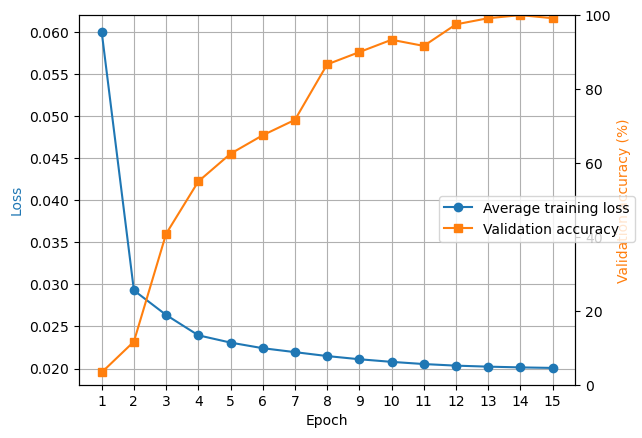

In [10]:
training_prompts = {p['positive'].split(' The answer')[0] for p in lines}
random.seed(7)
val_items = []
for eq_type in samples_per_type:
    picked = set()
    while len(picked) < 10:
        prompt, ans, _ = make_question(eq_type)
        if prompt not in training_prompts and prompt not in picked:
            picked.add(prompt)
            val_items.append((prompt, ans))
val_prompts = {p for p, _ in val_items}

def validation_accuracy(model):
    model.eval()
    correct = 0
    for prompt, ans in val_items:
        m = re.search(r"The answer is (\d+)", answer(model, prompt))
        correct += bool(m and int(m.group(1)) == ans)
    model.train()
    return correct / len(val_items)

total_steps = len(lines) // batch_size
epoch_loss, epoch_val_acc = [], []
best_val_acc = -1.0
open("train_log.txt", "w").close()
gpt.train()
for epoch in range(epochs):
    loss_history, margin_history = [], []
    pbar = tqdm(get_batches(lines, batch_size), total=total_steps, desc=f"epoch {epoch+1}/{epochs}", mininterval=30)
    for step, (neg_tensor, pos_tensor) in enumerate(pbar):
        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)
        loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * sft_weight

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        margin_history.append((pos_logprob - neg_logprob).mean().item())
        if step % 200 == 0:
            pbar.set_postfix(loss=f"{loss.item():.4f}")
    scheduler.step()
    epoch_loss.append(sum(loss_history) / len(loss_history))
    epoch_val_acc.append(validation_accuracy(gpt))
    msg = (f"epoch {epoch+1}: avg loss {epoch_loss[-1]:.4f}, "
           f"avg logp(pos)-logp(neg) {sum(margin_history)/len(margin_history):.3f}, "
           f"val acc {100*epoch_val_acc[-1]:.1f}%, lr now {scheduler.get_last_lr()[0]:.1e}")

    if epoch_val_acc[-1] > best_val_acc:
        best_val_acc = epoch_val_acc[-1]
        ckpt_path = f"./dpo.pt"
        torch.save({
            "model_state_dict": gpt.state_dict(),
            "model_args": ckpt['model_args'],
        }, ckpt_path)
        msg += f" -> saved checkpoint to {ckpt_path}"
    print(msg)
    with open("train_log.txt", "a") as f:
        f.write(msg + "\n")

print(f"Best validation accuracy: {100*best_val_acc:.1f}% (epoch {epoch_val_acc.index(best_val_acc)+1})")

fig, ax1 = plt.subplots()
ax1.plot(range(1, epochs + 1), epoch_loss, marker='o', color='tab:blue', label="Average training loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss", color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(range(1, epochs + 1), [100*a for a in epoch_val_acc], marker='s', color='tab:orange', label="Validation accuracy")
ax2.set_ylabel("Validation accuracy (%)", color='tab:orange')
ax2.set_ylim(0, 100)
ax1.set_xticks(range(1, epochs + 1))
ax1.grid(True)
fig.legend(loc="center right")
plt.show()

**Loss curve analysis.**

| Epoch | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 | 13 | 14 | 15 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Avg loss | .060 | .029 | .026 | .024 | .023 | .022 | .022 | .022 | .021 | .021 | .021 | .020 | .020 | .020 | .020 |
| Val acc (%) | 3.3 | 11.7 | 40.8 | 55.0 | 62.5 | 67.5 | 71.7 | 86.7 | 90.0 | 93.3 | 91.7 | 97.5 | 99.2 | **100.0** | 99.2 |

* **The loss falls sharply in epoch 1, then almost flattens.** The margin `logp(pos) - logp(neg)` is already about 6.7
  after the first epoch, so the preference term is nearly saturated: the model has learned to answer instead of
  refusing, and to use the `"The answer is … because … equals …"` template. From then on, the small remaining loss
  is mostly the SFT term on the positive answers.
* **Accuracy behaves very differently from the loss.** While the loss only drops from 0.026 to 0.020 after epoch 3,
  validation accuracy rises from 41% to 100%. The loss is averaged over every character of the answer, and the only
  characters that decide correctness are the few digits of the result. So we select the checkpoint by validation
  accuracy, not by loss.
* **Learning happens in two phases.** The first epochs learn the *format*: every answer is well-formed but the
  numbers are wrong. Then the model learns the *arithmetic*. This is why the template's 5 epochs at `lr = 1e-4`
  were not enough (see *Experiments*).
* **It keeps improving until the learning rate is almost 0.** The best epoch is 14 (100% of 120 validation
  questions), and that checkpoint is the one saved in `dpo.pt`. Each validation question is worth 0.8%, so small
  differences between late epochs are noise; the held-out test in 8.3 is the more reliable measure.

### Step 8: Begin testing

#### 8.1 Load the fine-tuned model and answer the example questions

We reload `dpo.pt` from disk, exactly as the TAs will, and answer the example prompts from the original notebook.

In [11]:
# Load the fine-tuned model
ckpt_path = "../dpo/dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])
gpt = GPT(gptconf).to(device)
try:
    state_dict = checkpoint['model']
except:
    state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
# Test
gpt.eval()
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?"]
with torch.no_grad():
    for prompt in test_set:
        print(answer(gpt, prompt))

17+19=? The answer is 36 because 17+19 equals 36.


3*17=? The answer is 51 because 3*17 equals 51.


72/4=? The answer is 18 because 72/4 equals 18.
72-x=34,x=? The answer is 38 because 72-34 equals 38.


x*11=44,x=? The answer is 4 because 44/11 equals 4.
3*17=? The answer is 51 because 3*17 equals 51.


72/4=? The answer is 18 because 72/4 equals 18.


72-x=34,x=? The answer is 38 because 72-34 equals 38.


#### 8.2 Held-out test set covering all 12 question types

To measure accuracy honestly we generate **20 new questions per type (240 in total)** with the same generator but
a different seed, and **reject any question that appears in the training or validation data**. The correct answer comes
straight from the generator, so we do not need to parse the question again (our first version parsed the
question and could only score `x+a=b` algebra).

In [12]:
random.seed(2024)
test_items = []
for eq_type in samples_per_type:
    chosen = set()
    while len(chosen) < 20:
        prompt, ans, _ = make_question(eq_type)
        if prompt not in training_prompts and prompt not in val_prompts and prompt not in chosen:
            chosen.add(prompt)
            test_items.append({"type": eq_type, "question": prompt, "correct_answer": ans})
print("Test questions:", len(test_items), "| overlap with training data:",
      sum(t['question'] in training_prompts for t in test_items))

Test questions: 240 | overlap with training data: 0


#### 8.3 Generate answers and score them

The predicted number is taken from `"The answer is <n>"`. A response counts as correct only if this number equals the
true answer. We print every response so the outputs can be inspected.

**Decoding strategy.** We use greedy decoding (`top_k=1`) rather than random sampling when generating model responses. This selects the character with the highest predicted probability at each step, producing consistent outputs for the same question. Greedy decoding is appropriate for mathematical evaluation because we are interested in accuracy rather than response diversity. However, selecting the most probable character does not guarantee a mathematically correct answer, since the model may assign higher probabilities to incorrect digits.

In [13]:
def extract(response):
    m = re.search(r"The answer is (-?\d+)", response)
    return int(m.group(1)) if m else None

for t in test_items:
    t["response"] = answer(gpt, t["question"])
    t["predicted_answer"] = extract(t["response"])
    t["correct"] = t["predicted_answer"] == t["correct_answer"]
    print(("✓ " if t["correct"] else "✗ ") + t["response"])

✓ 186+148=? The answer is 334 because 186+148 equals 334.


✓ 77+51=? The answer is 128 because 77+51 equals 128.
✓ 185+104=? The answer is 289 because 185+104 equals 289.


✓ 193+183=? The answer is 376 because 193+183 equals 376.


✓ 136+62=? The answer is 198 because 136+62 equals 198.


✓ 162+188=? The answer is 350 because 162+188 equals 350.


✓ 127+90=? The answer is 217 because 127+90 equals 217.


... (215 outputs left out)

✓ x/18=48,x=? The answer is 864 because 18*48 equals 864.
✓ x/22=62,x=? The answer is 1364 because 22*62 equals 1364.


✓ x/23=25,x=? The answer is 575 because 23*25 equals 575.
✓ x/5=59,x=? The answer is 295 because 5*59 equals 295.


✓ x/3=163,x=? The answer is 489 because 3*163 equals 489.


✓ x/17=123,x=? The answer is 2091 because 17*123 equals 2091.


type                     accuracy
addition                 20/20  (100.0%)
subtraction              20/20  (100.0%)
multiplication           19/20  ( 95.0%)
division                 18/20  ( 90.0%)
addition_unknown         20/20  (100.0%)
addition2_unknown        20/20  (100.0%)
subtraction_unknown      20/20  (100.0%)
subtraction2_unknown     20/20  (100.0%)
multiplication_unknown   18/20  ( 90.0%)
multiplication2_unknown  20/20  (100.0%)
division_unknown         19/20  ( 95.0%)
division2_unknown        18/20  ( 90.0%)

Overall: 232/240 = 96.7%
Responses in the expected 'The answer is ...' format: 240/240


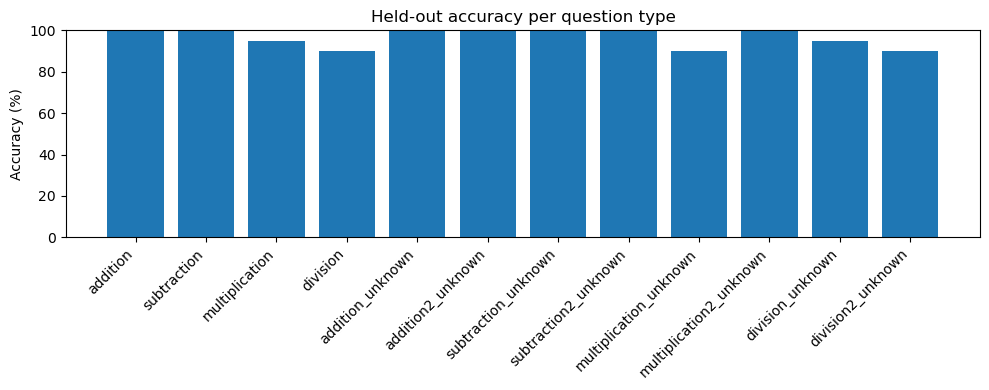

In [14]:
by_type = defaultdict(list)
for t in test_items:
    by_type[t["type"]].append(t["correct"])

print(f"{'type':24s} accuracy")
for eq_type, results in by_type.items():
    print(f"{eq_type:24s} {sum(results):2d}/{len(results)}  ({100*sum(results)/len(results):5.1f}%)")
overall = sum(t["correct"] for t in test_items) / len(test_items)
print(f"\nOverall: {sum(t['correct'] for t in test_items)}/{len(test_items)} = {100*overall:.1f}%")
formatted = sum(t["predicted_answer"] is not None for t in test_items)
print(f"Responses in the expected 'The answer is ...' format: {formatted}/{len(test_items)}")

plt.figure(figsize=(10, 4))
names = list(by_type)
plt.bar(range(len(names)), [100*sum(by_type[n])/len(by_type[n]) for n in names])
plt.xticks(range(len(names)), names, rotation=45, ha='right')
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.title("Held-out accuracy per question type")
plt.tight_layout()
plt.show()

#### 8.4 Error analysis

We analyse incorrect predictions by calculating the absolute difference between each predicted answer and its correct value. This helps us identify whether errors tend to be relatively small or large.

However, a small numerical difference does not necessarily mean the model has learned the correct mathematical procedure. Since NanoGPT predicts characters rather than performing explicit arithmetic, these errors may reflect incorrect digit predictions rather than specific calculation mistakes.

In [15]:
wrong = [t for t in test_items if not t["correct"] and t["predicted_answer"] is not None]
for eq_type in samples_per_type:
    errs = [abs(t["predicted_answer"] - t["correct_answer"]) for t in wrong if t["type"] == eq_type]
    if errs:
        close = sum(e <= 10 for e in errs)
        print(f"{eq_type:24s} wrong={len(errs):2d}  off by <=10: {close:2d}  median error: {sorted(errs)[len(errs)//2]}")

multiplication           wrong= 1  off by <=10:  0  median error: 20
division                 wrong= 2  off by <=10:  2  median error: 10
multiplication_unknown   wrong= 2  off by <=10:  2  median error: 5
division_unknown         wrong= 1  off by <=10:  1  median error: 6
division2_unknown        wrong= 2  off by <=10:  1  median error: 100


**Results analysis.**

* **Overall: 232/240 = 96.7%** on questions the model never saw. All 240 responses use the expected
  `"The answer is …"` format, and all 8 example prompts from the original notebook (8.1) are answered correctly.
* **Generalization and limitations.** The model achieves 96.7% accuracy on questions excluded from both the training and validation datasets. This indicates that it can answer previously unseen combinations of numbers within the mathematical formats it was trained on. However, the evaluation uses the same question templates and number ranges as training. Therefore, these results do not necessarily demonstrate that the model can solve unfamiliar mathematical problems or generalize to larger numbers. Further testing would be needed to establish this.
* **Comparison with our earlier models on exactly the same 240 questions.** *First model*: our first `dpo.pt`, trained on the
  unbalanced dataset. *Previous run*: the rebalanced dataset with 15 epochs, before we turned off dropout and
  oversampled the hardest types.

| Question type | First model | Previous run | Final model |
|---|---|---|---|
| `a+b` | 17 | 20 | **20** |
| `a-b` | 20 | 20 | **20** |
| `a*b` | 3 | 7 | **19** |
| `a/b` | 4 | 13 | **18** |
| `a+x=b`, `x+a=b` | 18, 18 | 19, 19 | **20, 20** |
| `a-x=b`, `x-a=b` | 18, 18 | 19, 20 | **20, 20** |
| `a*x=b`, `x*a=b` | 5, 3 | 15, 18 | **18, 20** |
| `a/x=b` | 7 | 19 | **19** |
| `x/a=b` | 3 | 6 | **18** |
| **Overall (out of 240)** | **134 (55.8%)** | **195 (81.2%)** | **232 (96.7%)** |

  (Each cell is the number correct out of 20.)

* **The two types we targeted improved the most.** `a*b` went from 35% to 95%, and `x/a=b` from 30% to 90%.
  Both need the model to compute a product of two numbers, and these are the two types we oversampled in Step 5.
* **Every remaining error is a single wrong digit.** For example `9*63 → 587` instead of 567, `994/7 → 132`
  instead of 142, and `x/7=85 → 695` instead of 595. These errors suggest that the model has learned useful numerical patterns, as most incorrect answers are close to the expected values. However, we cannot conclude that it has learned the underlying arithmetic procedures. Since NanoGPT generates answers character by character, the remaining errors may reflect incorrect digit predictions rather than specific carrying or borrowing mistakes.
* **Addition, subtraction and all four `+`/`-` algebra forms are perfect** (120/120).
* Part of the gap between the first model and the later ones on `*` and `/` comes from the test using wider operand
  ranges: the first model never saw a multiplier above 20.

## Experiments

Before reaching the final setup we tried several alternatives. We report them because they explain our design
choices. All accuracies are on held-out questions of all 12 types.

| # | What we changed | Epochs | Held-out accuracy |
|---|---|---|---|
| 1 | Our first notebook re-run from scratch exactly as written (first dataset, template settings: `lr = 1e-4`, StepLR) | 5 | 7.1% |
| 2 | Rebalanced dataset, template settings, negatives = the pretrained model's own refusal `"Sorry, I don't know."` | 5 | 6.7% |
| 3 | **Standard DPO** with a frozen reference model, response-only summed log-probs, 50% *hard negatives* (`"The answer is <wrong number>."`), SFT weight 1.0, cosine schedule | 3 (stopped) | 6.7% |
| 4 | Rebalanced dataset, template loss, **15 epochs, `lr = 3e-4`, cosine**, best-validation checkpoint (60 validation questions) | 15 | 81.2% |
| **Final** | As 4, plus **dropout switched off** and **oversampling of `a*b` and `x/a=b`**, 120 validation questions | 15 | **96.7%** |

**What we learned.**
1. **The training budget was the first bottleneck.** Runs 1–3 are very different, but they all end at about 7%:
   they learn the answer format and stop before learning the digits. Only with more epochs and a higher learning
   rate does accuracy take off (run 4). Runs 2–3 were therefore compared at a point where no method had learned
   arithmetic yet, so they do **not** show that those ideas are worse. Hard negatives with proper DPO could still
   help with a longer run, but we did not have the compute to test this (each epoch takes about 11 minutes on a
   laptop GPU).
2. **Removing dropout and oversampling the weakest types gave a further +15.5 points** (run 4 → final). The final
   run also learned faster: 41% validation accuracy after 3 epochs, against 5% in run 4. We changed both things in
   the same run, so we cannot say how much each one contributed on its own. The faster start fits the dropout
   change, which affects every question type. The large gains on `a*b` and `x/a=b` specifically fit the oversampling.
3. **Generating negatives with the pretrained model adds nothing here.** It answers 96% of math questions with the
   same refusal (Task 1.1), so its "generated negatives" are one fixed string.

## Summary

* **Task 1: data.** 101,000 unique positive/negative pairs over 12 question types (4 arithmetic operations and
  8 algebra forms), with answers computed exactly in Python. We rebalanced the types so that multiplication and
  division have 2–3× more examples than in our first version. Every pair is validated: vocabulary, length, and
  correctness of each arithmetic answer.
* **Task 2: training.** The template DPO loss with an SFT term, AdamW, and cosine decay from `3e-4` over 15 epochs,
  with dropout switched off and the two hardest question types shown twice per epoch. A 120-question validation set
  is checked after every epoch, and only the best checkpoint is saved to `dpo.pt` (epoch 14, 100% validation
  accuracy).
* **Task 3: testing.** All 8 example prompts are answered correctly. On 240 unseen questions covering all 12 types
  the model scores **96.7%**, against **55.8%** for our first model on the same questions. Every type is at 90% or
  above, and the 8 remaining errors are each a single wrong digit.
* **Our main improvements over the template:**
  1. a rebalanced, larger set of multiplication and division questions;
  2. a longer training schedule with a higher learning rate, since the 5-epoch template only learns the answer format;
  3. dropout switched off for fine-tuning, and oversampling of the question types the model found hardest;
  4. checkpoint selection by validation accuracy instead of saving the last epoch;
  5. a held-out test covering all 12 question types, with zero overlap with training, plus per-type error analysis.
* **Possible next steps:** separate the effects of removing dropout and of oversampling with one run each; retest
  hard negatives with standard DPO under the longer schedule; and test larger numbers than the training ranges to
  see how far the learned arithmetic generalises.